In [15]:
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from src.models import *
from src.utils import *

In [16]:
if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

torch.manual_seed(0)

transform = torchvision.transforms.Compose([torchvision.transforms.Resize((224,224)),
                            torchvision.transforms.ToTensor()])

In [17]:
pil_img1 = Image.open('./test_images/Fish3.JPEG').convert('RGB')
pil_img2 = Image.open('./test_images/Fish2.JPEG').convert('RGB')

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x2 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)

x1 = x1[None,...].to(device)
x2 = x2[None,...].to(device)

In [29]:
architectures = ['ResNET-50']
p = []

for architecture in architectures:

    if architecture == 'VGG-16':
        model = VGG_emb(level='full')
        model = model.to(device)
        model.eval()
    elif architecture == 'ResNET-50':
        model = ResNET_emb(level='full')
        model = model.to(device)
        model.eval()
    elif architecture == 'ViTb-16':
        model = ViT16_emb()
        model = model.to(device)
        model.eval()
    elif architecture == 'Dino':
        model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
        model = model.to(device)
        model.eval()

    p.append(compute_saliency(x=x2, x_target=x2, model=model, n_masks=20, beta=20, return_negative=False, learnable_param=True))

    # del model

In [30]:
saliency = p[0]

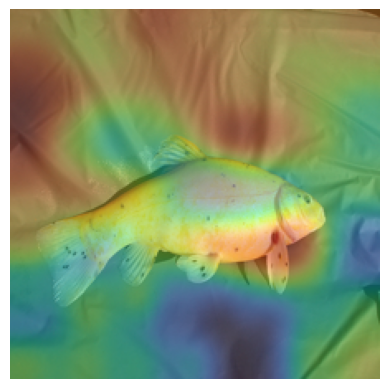

In [33]:
plt.imshow(pil_img2.resize((224,224)))
plt.imshow(saliency, cmap='turbo', alpha=0.4)
plt.axis('off')
plt.show()

In [21]:
# f, ax = plt.subplots(1,len(p)+1, figsize=(16,20))

# cm = 'viridis'
# alph = 0.5

# ax[0].imshow(pil_img1.resize((224,224)))
# ax[0].axis('off')

# for i,architecture in enumerate(architectures):

#     ax[i+1].imshow(pil_img1.resize((224,224)))
#     ax[i+1].imshow(p[i], cmap=cm, alpha=alph)
#     ax[i+1].title.set_text(architecture)
#     ax[i+1].axis('off')

# plt.show()

In [22]:
# levels = [1,2,3,'full']
# p = []

# f, ax = plt.subplots(1,4, figsize=(16,20))

# cm = 'Reds'
# alph = 0.5

# for i,level in enumerate(levels):
#     model = VGG_emb(level=level)
#     model = model.to(device)
#     model.eval()

#     p.append(compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, beta=1, return_negative=False))

#     ax[i].imshow(pil_img1.resize((224,224)))
#     ax[i].imshow(p[i], cmap=cm, alpha=alph)
#     ax[i].title.set_text(str(level))
#     ax[i].axis('off')

#     del model

In [23]:
# model = ViT16_emb()
# model = model.to(device)
# model.eval()

# betas = [1,10, 100]
# p = []

# for i,beta in enumerate(betas):
#     p.append(compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, beta=beta, return_negative=False))

In [24]:
# f, ax = plt.subplots(1,len(betas)+1, figsize=(16,20))
# ax[0].imshow(pil_img1.resize((224,224)))
# ax[0].axis('off')

# cm = 'viridis'
# alph = 0.6

# for i,beta in enumerate(betas):

#     ax[i+1].imshow(pil_img1.resize((224,224)))
#     ax[i+1].imshow(p[i], cmap=cm, alpha=alph)
#     ax[i+1].title.set_text(r'$\beta$ = ' + str(beta) + '/k')
#     ax[i+1].axis('off')

In [25]:
beta = 1
phi = 1

In [26]:
beta == None or phi == None

False

In [27]:
loss_inf = InfoLoss(beta=beta, phi=1)

In [28]:
loss_inf.to(device)

InfoLoss()